# Social Network Analysis Metrics: Centrality Analysis
**Course:** Advanced Text and Social Media Analytics (ATSMA) Lab
**Topic 5:** Core Centrality Metrics: Degree, Closeness, Betweenness, Eigenvector (and PageRank)

---
## Objective
Social networks are made of **nodes** (people / accounts) and **edges** (friendships / follows / interactions).
A central question in SNA is: **which nodes are the most important, and in what sense?**
"Important" has several meanings, so we use four different centrality metrics:

| Metric | Question it answers | Typical role |
|---|---|---|
| Degree | Who has the most direct connections? | Popular hub |
| Closeness | Who can reach everyone the fastest? | Efficient broadcaster |
| Betweenness | Who sits on the paths between others? | Bridge / gatekeeper |
| Eigenvector | Who is connected to other important nodes? | Influencer |

**Dataset:** Zachary's Karate Club (1977), 34 members of a university karate club.
Ties = pairs who socialised outside the club. During the study the club split into two factions, one led by the
instructor (**node 0, "Mr. Hi"**) and one by the administrator/officer (**node 33, "John A."**).
This is the same network as `soc-karate` on Network Repository.

**Notebook outline:** 1. Load data → 2. Network statistics → 3. The four centralities (theory + code) →
4. Verify with from-scratch code → 5. Compare metrics → 6. Communities → 7. Robustness experiment →
8. Directed networks (in/out degree) → 9. Conclusions

## 1. Setup and Data Loading

In [1]:
# pip install networkx pandas matplotlib numpy scipy
import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque

plt.rcParams["figure.dpi"] = 110
pd.set_option("display.precision", 4)

We load the Karate Club graph that ships with NetworkX. To use **your own file** (for example the `soc-karate.mtx`
downloaded from Network Repository, or any edge list), change `DATA_SOURCE` below.

In [3]:
def load_graph(source="karate", directed=False):
    """source = 'karate' | 'lesmis' | 'florentine' | path to .mtx / edge-list file"""
    builtin = {
        "karate": nx.karate_club_graph,
        "lesmis": nx.les_miserables_graph,
        "florentine": nx.florentine_families_graph,
    }
    if source in builtin:
        return builtin[source]()
    create = nx.DiGraph if directed else nx.Graph
    if source.lower().endswith(".mtx"):                      # Network Repository format
        from scipy.io import mmread
        return nx.from_scipy_sparse_array(mmread(source).tocsr(), create_using=create)
    lines = []                                               # plain edge list: 'u v' or 'u,v'
    for ln in open(source):
        ln = ln.strip()
        if ln and ln[0] not in "%#":
            lines.append(ln.replace(",", " "))
    return nx.parse_edgelist(lines, nodetype=str, create_using=create, data=False)

DATA_SOURCE = "karate"          # <-- change to e.g. "soc-karate.mtx"
G = load_graph(DATA_SOURCE)
print(G)

Graph named "Zachary's Karate Club" with 34 nodes and 78 edges


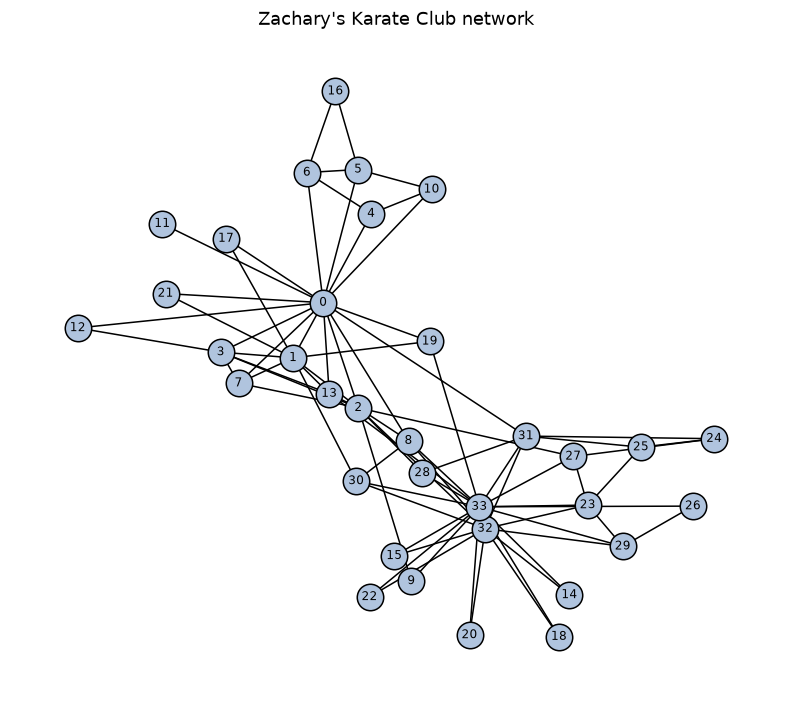

In [4]:
pos = nx.spring_layout(G, seed=42)           # fixed layout so every plot looks the same
plt.figure(figsize=(7, 6))
nx.draw(G, pos, with_labels=True, node_color="lightsteelblue", edgecolors="black", font_size=8)
plt.title("Zachary's Karate Club network")
plt.show()

## 2. Basic Network Statistics
Before computing centralities, describe the overall structure of the network.

- **Density** = actual edges ÷ possible edges. Low density means a sparse network.
- **Diameter** = the longest shortest path; **average path length** shows how "small" the world is.
- **Clustering coefficient** = how often a node's friends are also friends with each other (triangles).

In [5]:
U = G.to_undirected()
giant = U.subgraph(max(nx.connected_components(U), key=len))
stats = {
    "Nodes": G.number_of_nodes(),
    "Edges": G.number_of_edges(),
    "Density": nx.density(G),
    "Average degree": 2 * U.number_of_edges() / U.number_of_nodes(),
    "Connected components": nx.number_connected_components(U),
    "Diameter": nx.diameter(giant),
    "Average shortest path": nx.average_shortest_path_length(giant),
    "Average clustering": nx.average_clustering(U),
    "Transitivity": nx.transitivity(U),
}
pd.Series(stats, name="value").to_frame()

,value
Nodes,34.0000
Edges,78.0000
Density,0.1390
Average degree,4.5882
Connected components,1.0000
Diameter,5.0000
Average shortest path,2.4082
Average clustering,0.5706
Transitivity,0.2557


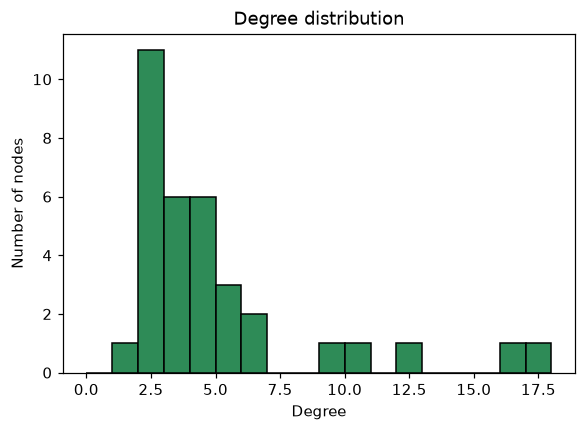

In [6]:
degs = [d for _, d in G.degree()]
plt.figure(figsize=(6, 4))
plt.hist(degs, bins=range(0, max(degs) + 2), color="seagreen", edgecolor="black")
plt.xlabel("Degree"); plt.ylabel("Number of nodes"); plt.title("Degree distribution")
plt.show()

**Reading the result:** the network is sparse (density ≈ 0.14) but small-world (diameter 5, average path ≈ 2.4)
and highly clustered. Most members have few ties while a handful of nodes have many, a typical social-network pattern.

## 3. The Four Centrality Metrics
A helper first: a function that draws the network with **node size and colour proportional to a score**.

In [7]:
def draw_scores(G, scores, title, cmap="viridis"):
    s = pd.Series(scores).reindex(G.nodes())
    sizes = 150 + 2500 * (s - s.min()) / (s.max() - s.min() + 1e-12)
    plt.figure(figsize=(8, 6))
    nx.draw_networkx_edges(G, pos, alpha=0.3)
    nodes = nx.draw_networkx_nodes(G, pos, node_size=sizes, node_color=s.values, cmap=cmap, edgecolors="black")
    nx.draw_networkx_labels(G, pos, font_size=7)
    plt.colorbar(nodes, label="score"); plt.title(title); plt.axis("off"); plt.show()

def top(scores, k=5):
    return pd.Series(scores).sort_values(ascending=False).head(k).to_frame("score")

### 3a. Degree Centrality
**Idea:** count direct connections. More ties means more popularity or activity.

$$C_D(v) = \frac{\deg(v)}{n-1}$$

For **directed** networks it splits into **in-degree** (incoming ties, popularity) and **out-degree** (outgoing ties, activity).
Section 8 shows this on a directed network.

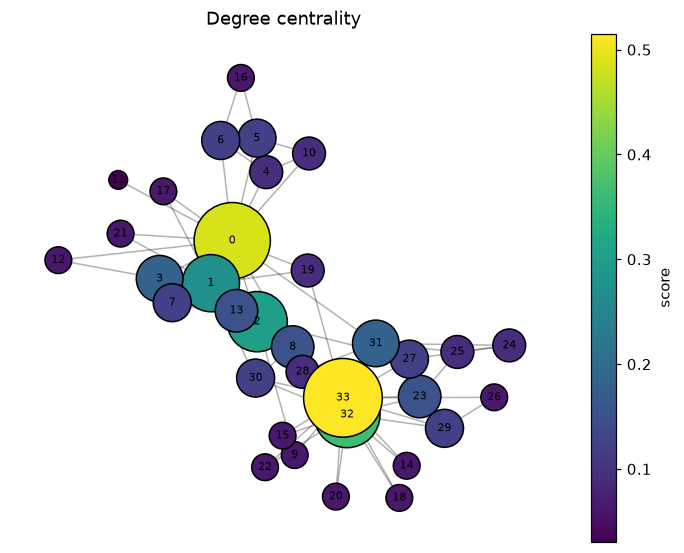

,score
33,0.5152
0,0.4848
32,0.3636
2,0.3030
1,0.2727


In [8]:
deg_c = nx.degree_centrality(G)
draw_scores(G, deg_c, "Degree centrality")
top(deg_c)

### 3b. Closeness Centrality
**Idea:** how near is a node to everyone else? It is the inverse of the *average* shortest-path distance.

$$C_C(v) = \frac{n-1}{\sum_{u \neq v} d(v,u)}$$

High closeness means information from this node reaches the whole network in few steps.

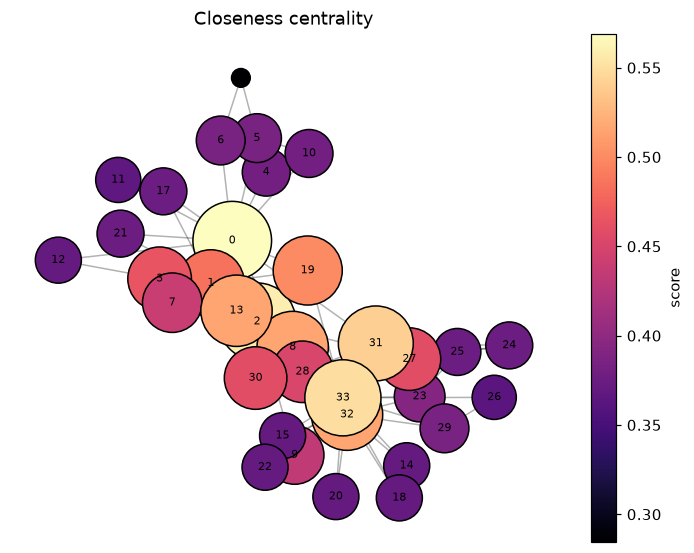

,score
0,0.5690
2,0.5593
33,0.5500
31,0.5410
13,0.5156


In [9]:
clo_c = nx.closeness_centrality(G)
draw_scores(G, clo_c, "Closeness centrality", cmap="magma")
top(clo_c)

### 3c. Betweenness Centrality
**Idea:** how often does a node lie on the shortest path between two other nodes?

$$C_B(v) = \sum_{s \neq v \neq t} \frac{\sigma_{st}(v)}{\sigma_{st}}$$

where $\sigma_{st}$ is the number of shortest paths from $s$ to $t$, and $\sigma_{st}(v)$ is how many of them pass through $v$.
High betweenness marks **brokers**: remove them and groups get cut off from each other.

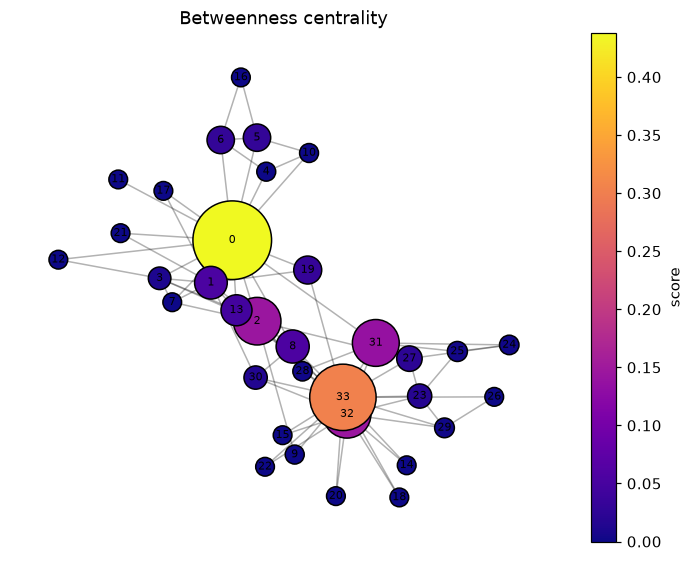

,score
0,0.4376
33,0.3041
32,0.1452
2,0.1437
31,0.1383


In [10]:
bet_c = nx.betweenness_centrality(G, normalized=True)
draw_scores(G, bet_c, "Betweenness centrality", cmap="plasma")
top(bet_c)

### 3d. Eigenvector Centrality (and PageRank)
**Idea:** a connection to an important node counts for more than a connection to an unimportant one.
A node's score is proportional to the sum of its neighbours' scores:

$$x_v = \frac{1}{\lambda}\sum_{u \in N(v)} x_u \quad\Longleftrightarrow\quad A\mathbf{x} = \lambda \mathbf{x}$$

So the scores form the **leading eigenvector** of the adjacency matrix $A$.

**PageRank** (Google) is a famous variant: it adds a damping factor $\alpha$ (random jumps) and, in directed graphs,
divides each node's score among the nodes it points to.

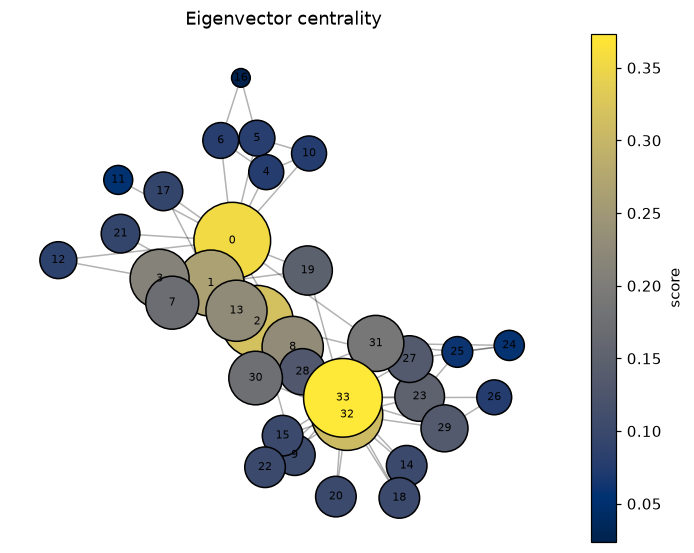

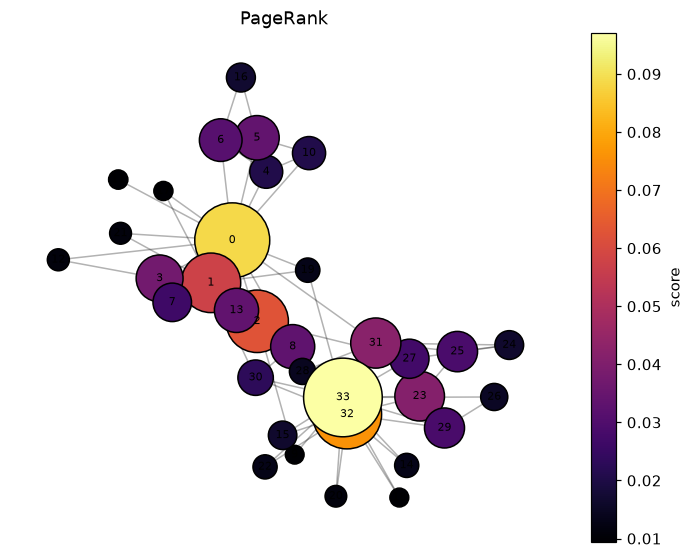

,eigenvector_score,pagerank_score
33,0.3734,0.0970
0,0.3555,0.0885
2,0.3172,0.0628
32,0.3087,0.0759
1,0.2660,0.0574


In [11]:
eig_c = nx.eigenvector_centrality(G, max_iter=1000)
pr_c  = nx.pagerank(G, alpha=0.85)
draw_scores(G, eig_c, "Eigenvector centrality", cmap="cividis")
draw_scores(G, pr_c,  "PageRank", cmap="inferno")
pd.concat([top(eig_c).add_prefix("eigenvector_"), top(pr_c).add_prefix("pagerank_")], axis=1)

### 3e. All metrics in one table

In [12]:
df = pd.DataFrame({
    "degree": deg_c, "closeness": clo_c, "betweenness": bet_c,
    "eigenvector": eig_c, "pagerank": pr_c, "clustering": nx.clustering(G),
})
df.index.name = "node"
df.sort_values("degree", ascending=False).head(10)

,degree,closeness,betweenness,eigenvector,pagerank,clustering
node,,,,,,
33,0.5152,0.5500,0.3041,0.3734,0.0970,0.1103
0,0.4848,0.5690,0.4376,0.3555,0.0885,0.1500
32,0.3636,0.5156,0.1452,0.3087,0.0759,0.1970
2,0.3030,0.5593,0.1437,0.3172,0.0628,0.2444
1,0.2727,0.4853,0.0539,0.2660,0.0574,0.3333
3,0.1818,0.4648,0.0119,0.2112,0.0372,0.6667
31,0.1818,0.5410,0.1383,0.1910,0.0420,0.2000
23,0.1515,0.3929,0.0176,0.1501,0.0411,0.4000
8,0.1515,0.5156,0.0559,0.2274,0.0334,0.5000


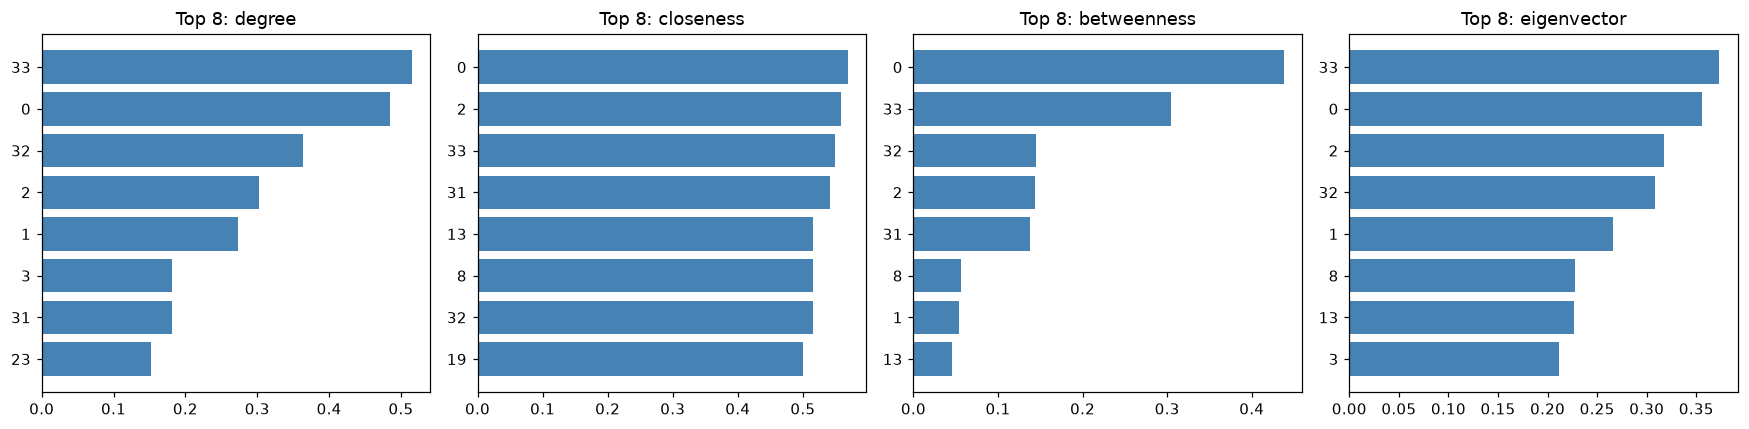

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, m in zip(axes, ["degree", "closeness", "betweenness", "eigenvector"]):
    s = df[m].sort_values(ascending=False).head(8)[::-1]
    ax.barh([str(i) for i in s.index], s.values, color="steelblue")
    ax.set_title(f"Top 8: {m}")
plt.tight_layout(); plt.show()

In [14]:
desc = {"degree": "most connected (hub)", "closeness": "reaches everyone fastest",
        "betweenness": "key bridge / gatekeeper", "eigenvector": "linked to other important nodes",
        "pagerank": "highest random-walk importance"}
for m, text in desc.items():
    print(f"{m:12s} -> node {df[m].idxmax():>2}  ({df[m].max():.3f})  {text}")

degree       -> node 33  (0.515)  most connected (hub)
closeness    -> node  0  (0.569)  reaches everyone fastest
betweenness  -> node  0  (0.438)  key bridge / gatekeeper
eigenvector  -> node 33  (0.373)  linked to other important nodes
pagerank     -> node 33  (0.097)  highest random-walk importance


**Interpretation:** nodes **0** and **33** dominate every ranking, which matches the two faction leaders in Zachary's study.
Node 33 has the *most ties* (degree, eigenvector, PageRank) but node 0 is the better *bridge and broadcaster*
(closeness, betweenness). Different metrics reward different kinds of importance.

## 4. How the Metrics Actually Work: From-Scratch Implementations
To show we understand the algorithms, we implement them without NetworkX's centrality functions and check that
the results match.

- **Closeness:** Breadth-First Search (BFS) gives shortest distances from a node to all others.
- **Betweenness:** Brandes' algorithm. One BFS per source node counts shortest paths ($\sigma$), then walks back
  accumulating each node's share of dependency.
- **Eigenvector:** power iteration, i.e. repeatedly multiply by $A$ and normalise until the vector stops changing.

In [15]:
def bfs_distances(adj, source):
    dist, q = {source: 0}, deque([source])
    while q:
        u = q.popleft()
        for v in adj[u]:
            if v not in dist:
                dist[v] = dist[u] + 1
                q.append(v)
    return dist

def manual_degree(G):
    n = G.number_of_nodes()
    return {v: G.degree(v) / (n - 1) for v in G}

def manual_closeness(G):
    n = G.number_of_nodes()
    adj = {v: list(G.neighbors(v)) for v in G}
    out = {}
    for v in G:
        d = bfs_distances(adj, v)
        total, reach = sum(d.values()), len(d) - 1
        out[v] = (reach / total) * (reach / (n - 1)) if total > 0 else 0.0
    return out

def manual_betweenness(G):
    adj = {v: list(G.neighbors(v)) for v in G}
    bc = dict.fromkeys(G, 0.0)
    for s in G:
        stack, pred = [], {v: [] for v in G}
        sigma, dist = dict.fromkeys(G, 0.0), dict.fromkeys(G, -1)
        sigma[s], dist[s] = 1.0, 0
        q = deque([s])
        while q:                                   # forward pass: count shortest paths
            v = q.popleft(); stack.append(v)
            for w in adj[v]:
                if dist[w] < 0:
                    dist[w] = dist[v] + 1; q.append(w)
                if dist[w] == dist[v] + 1:
                    sigma[w] += sigma[v]; pred[w].append(v)
        delta = dict.fromkeys(G, 0.0)
        while stack:                               # backward pass: accumulate dependencies
            w = stack.pop()
            for v in pred[w]:
                delta[v] += sigma[v] / sigma[w] * (1 + delta[w])
            if w != s:
                bc[w] += delta[w]
    n = G.number_of_nodes()
    return {v: bc[v] / ((n - 1) * (n - 2)) for v in bc}   # normalise (undirected pairs counted twice)

def manual_eigenvector(G, iters=1000, tol=1e-9):
    nodes = list(G.nodes())
    A = nx.to_numpy_array(G, nodelist=nodes, weight=None)
    x = np.ones(len(nodes)) / len(nodes)
    for _ in range(iters):
        x_new = A @ x + x                          # (A + I) avoids oscillation, same eigenvectors
        x_new /= np.linalg.norm(x_new)
        if np.linalg.norm(x_new - x) < tol:
            x = x_new; break
        x = x_new
    return dict(zip(nodes, x))

In [15]:
checks = {"degree": manual_degree, "closeness": manual_closeness,
          "betweenness": manual_betweenness, "eigenvector": manual_eigenvector}
rows = []
for name, fn in checks.items():
    mine = pd.Series(fn(G))
    err = float(np.abs(mine - df[name]).max())
    rows.append({"metric": name, "max abs difference vs NetworkX": err, "match": err < 1e-4})
pd.DataFrame(rows).set_index("metric")

,max abs difference vs NetworkX,match
metric,,
degree,0.0000e+00,True
closeness,0.0000e+00,True
betweenness,5.5511e-17,True
eigenvector,7.9493e-06,True


All four from-scratch versions agree with NetworkX (differences ≈ 0), so the formulas above are implemented correctly.

## 5. Comparing the Metrics
Do the metrics rank nodes the same way? We use **Spearman rank correlation** (it compares rankings, not raw scores).

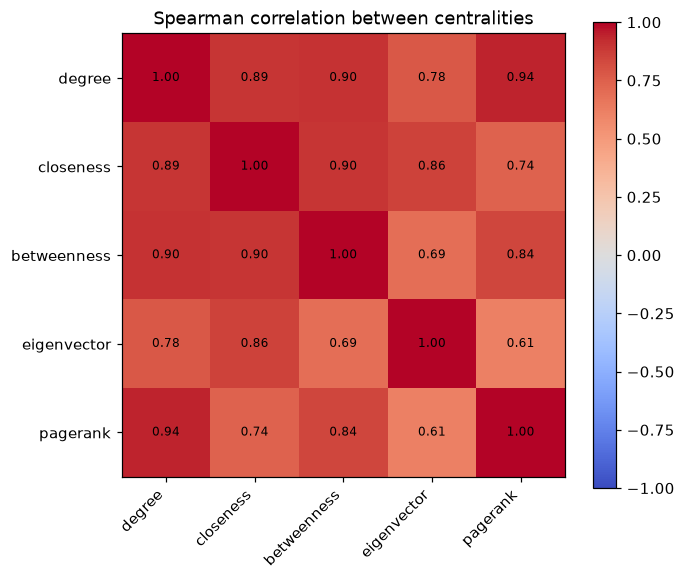

In [16]:
cols = ["degree", "closeness", "betweenness", "eigenvector", "pagerank"]
corr = df[cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=45, ha="right"); ax.set_yticks(range(len(cols)), cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im); plt.title("Spearman correlation between centralities"); plt.show()

**Interpretation:** the metrics are strongly but not perfectly correlated (≈ 0.6 to 0.9). Highly connected nodes tend to be
close and influential, but the differences matter: a node can be a bridge without being a hub. That is why we report
several metrics rather than just one.

## 6. Communities and Roles
Centrality tells us *who* matters; community detection tells us *which group* they belong to.
We use **greedy modularity maximisation**. Modularity measures how much denser the links inside groups are than expected by chance.

3 communities, modularity = 0.411


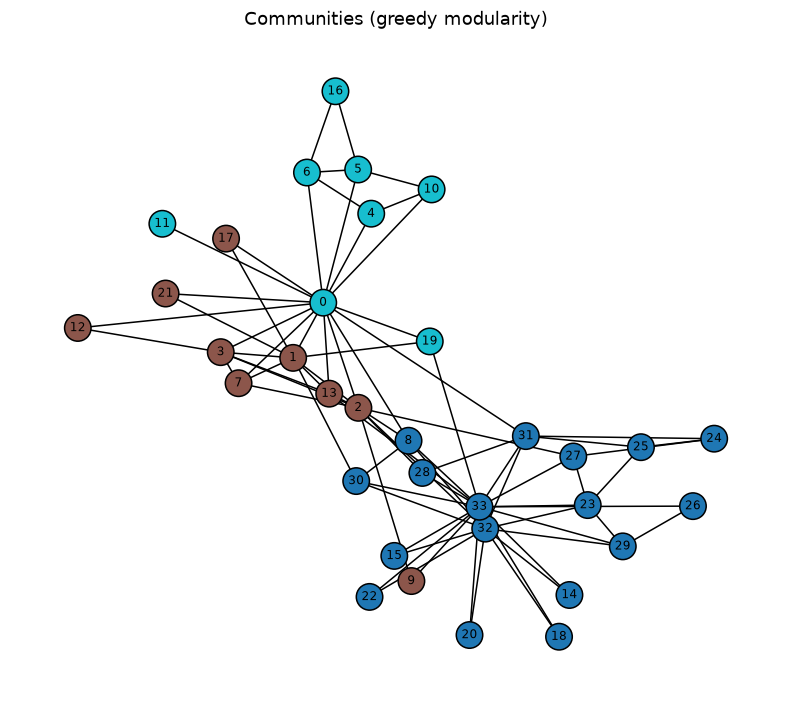

,degree,closeness,betweenness,eigenvector
community,,,,
0,0.1390,0.4255,0.0417,0.1485
1,0.1414,0.4467,0.0285,0.1737
2,0.1364,0.4058,0.0664,0.1113


In [17]:
comms = nx.community.greedy_modularity_communities(G)
label = {v: i for i, c in enumerate(comms) for v in c}
df["community"] = pd.Series(label)
print(f"{len(comms)} communities, modularity = {nx.community.modularity(G, comms):.3f}")

plt.figure(figsize=(7, 6))
nx.draw(G, pos, node_color=[label[v] for v in G], cmap="tab10", with_labels=True,
        font_size=8, edgecolors="black")
plt.title("Communities (greedy modularity)"); plt.show()

df.groupby("community")[["degree", "closeness", "betweenness", "eigenvector"]].mean()

In [18]:
# Compare with the real historical split recorded in the dataset ('club' attribute)
truth = {v: G.nodes[v]["club"] for v in G} if "club" in G.nodes[0] else None
if truth:
    ct = pd.crosstab(pd.Series(label, name="detected community"), pd.Series(truth, name="actual faction"))
    display(ct)

actual faction,Mr. Hi,Officer
detected community,,
0,1,16
1,8,1
2,8,0


**Interpretation:** the algorithm finds 3 communities, while history recorded 2 factions. Community 0 holds 16 of the 17 Officer-faction
members, and communities 1 and 2 together hold 16 of the 17 Mr. Hi-faction members. So the detected groups are a finer-grained version of
the real split: merging communities 1 and 2 would give 32 of 34 members correctly placed.

## 7. Robustness Experiment: What Happens if Central Nodes Disappear?
We remove nodes one by one, **highest score first** for each metric, plus a **random** baseline averaged over 30 runs.
We track the size of the largest connected component. A fast drop means the metric found nodes that hold the network together.

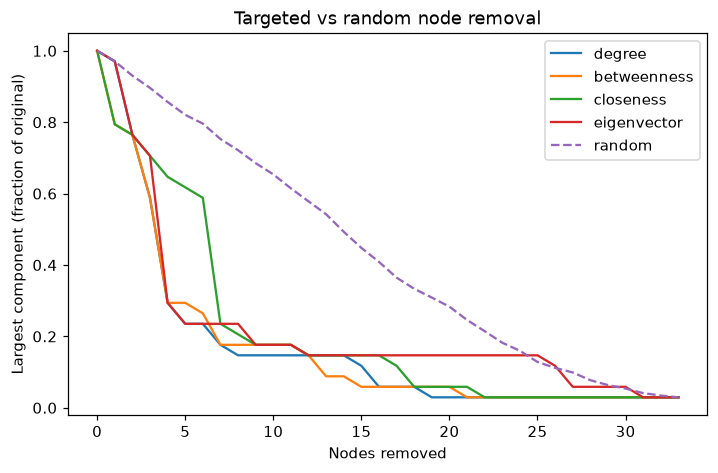

In [18]:
def lcc_fraction(H, n):
    return len(max(nx.connected_components(H), key=len)) / n if H.number_of_nodes() else 0

def attack_curve(G, order):
    H, n = G.copy(), G.number_of_nodes()
    curve = [lcc_fraction(H, n)]
    for v in order[: n - 1]:
        H.remove_node(v); curve.append(lcc_fraction(H, n))
    return curve

curves = {m: attack_curve(G, df[m].sort_values(ascending=False).index.tolist())
          for m in ["degree", "betweenness", "closeness", "eigenvector"]}
rng = np.random.default_rng(42)
rand_runs = [attack_curve(G, list(rng.permutation(list(G.nodes())))) for _ in range(30)]
curves["random"] = np.mean(rand_runs, axis=0)

plt.figure(figsize=(7.5, 4.5))
for m, c in curves.items():
    plt.plot(c, label=m, linestyle="--" if m == "random" else "-")
plt.xlabel("Nodes removed"); plt.ylabel("Largest component (fraction of original)")
plt.title("Targeted vs random node removal"); plt.legend(); plt.show()

**Interpretation:** removing the most central nodes breaks the network apart much faster than removing random nodes.
Social networks are robust to random failure but vulnerable to targeted removal of hubs and brokers.

## 8. Directed Networks: In-Degree vs Out-Degree
Karate Club is **undirected**, so it cannot show the in/out split from the topic description.
Here we use a small **directed** demo network (a scale-free directed graph, like "who follows whom" on social media).
Replace it with a real directed dataset, e.g. SNAP's *Email-Eu-core* or *Wiki-Vote*, via
`load_graph("file.txt", directed=True)`.

Most popular (in-degree):


,in_degree,out_degree,pagerank,betweenness
2,0.6271,0.0847,0.2252,0.1002
0,0.1525,0.1017,0.1404,0.0424
1,0.1525,0.0339,0.0855,0.0254
13,0.0678,0.0339,0.0725,0.0079
3,0.0508,0.0339,0.0659,0.0178


Most active (out-degree):


,in_degree,out_degree,pagerank,betweenness
0,0.1525,0.1017,0.1404,0.0424
2,0.6271,0.0847,0.2252,0.1002
4,0.0508,0.0508,0.0622,0.0172
11,0.0000,0.0508,0.0042,0.0000
1,0.1525,0.0339,0.0855,0.0254


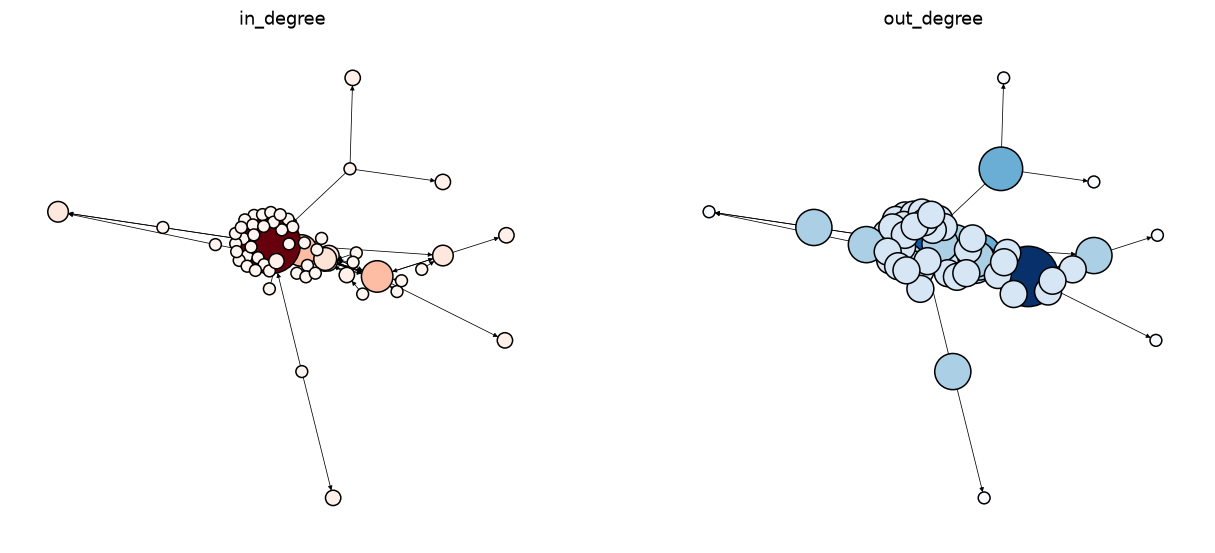

In [19]:
D = nx.DiGraph(nx.scale_free_graph(60, seed=7))        # collapse multi-edges
D.remove_edges_from(nx.selfloop_edges(D))
dpos = nx.spring_layout(D, seed=3)

dd = pd.DataFrame({
    "in_degree":  nx.in_degree_centrality(D),    # incoming ties = popularity / audience
    "out_degree": nx.out_degree_centrality(D),   # outgoing ties = activity
    "pagerank":   nx.pagerank(D, alpha=0.85),
    "betweenness": nx.betweenness_centrality(D),
})
print("Most popular (in-degree):"); display(dd.nlargest(5, "in_degree"))
print("Most active (out-degree):"); display(dd.nlargest(5, "out_degree"))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, m, cm in zip(axes, ["in_degree", "out_degree"], ["Reds", "Blues"]):
    s = dd[m].reindex(D.nodes())
    nx.draw(D, dpos, node_size=60 + 1500 * s / s.max(), node_color=s.values, cmap=cm,
            edgecolors="black", arrowsize=6, width=0.5, ax=ax)
    ax.set_title(m)
plt.show()

**Interpretation:** in a directed network a node can be very *popular* (high in-degree) without being *active* (low out-degree),
like an influencer who is followed by many but follows few. PageRank builds on in-links and weights each link by the importance of who sent it.

## 9. Export Results and Conclusions

In [ ]:
df.sort_values("degree", ascending=False).to_csv("centrality_scores.csv", index_label="node")
print("Saved centrality_scores.csv")

Saved centrality_scores.csv


: 

### Conclusions
1. **Degree** identifies the most connected members (node 33 first, then node 0).
2. **Closeness** and **betweenness** favour node 0, who is the most efficient broadcaster and the main bridge between groups.
3. **Eigenvector centrality** and **PageRank** reward being tied to other well-connected nodes (nodes 33, 0, 2, 32).
4. The metrics are correlated but not interchangeable, so a full analysis needs all of them.
5. Targeted removal of central nodes fragments the network faster than random removal.
6. Our from-scratch implementations of BFS-based closeness, Brandes betweenness and power-iteration eigenvector centrality
   match NetworkX, which confirms the underlying mathematics.
7. Community detection finds 3 groups that refine the historical 2-faction split (the Officer's faction is almost one community; Mr. Hi's faction splits into two).

### Limitations and Future Work
- Karate Club is small (34 nodes) and undirected; results on larger real social-media graphs (Twitter/Reddit reply
  networks, SNAP datasets) may differ, and exact betweenness becomes slow beyond about 10,000 nodes (use sampling with `k=`).
- Centrality describes structure only; combining it with text analytics (topics, sentiment of what influential nodes post)
  is a natural extension for ATSMA.

### References
- Zachary, W. W. (1977). *An information flow model for conflict and fission in small groups.* Journal of Anthropological Research.
- Brandes, U. (2001). *A faster algorithm for betweenness centrality.* Journal of Mathematical Sociology.
- Network Repository: soc-karate. Kaggle: *Fundamentals of Social Network Analysis (SNA)* by mexwell.
- NetworkX documentation: centrality algorithms.